<a href="https://colab.research.google.com/github/SamyraLB/Projeto-Segmentacao-de-Clientes-utilizando-Big-Data-Python/blob/main/Seg_Clientes_BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
import plotly.express as px
import matplotlib.pyplot as plt

# LEITURA E ANALISE EXPLORATORIA DOS DADOS


#### VISUALIZAÇÃO DO DATASET

A seguir estão algumas das principais colunas do dataset:

- **DTFAT:**  Data do Pedido
- **CODCLI:**  Código Identificador do Cliente
- **CHAVE_SUB:**  Concatenação de CodSec, CodCategoria e CodSubcategoria
- **CODSEC:**  Código Identificador da Seção
- **NOME_SECAO:**  Nome Referente à Seção
- **CODCATEGORIA:**  Código Identificador da Categoria
- **NOME_CATEGORIA:**  Nome Referente à Categoria
- **CODSUBCATEGORIA:**  Código Identificador da Subcategoria
- **NOME_SUBCATEGORIA:**  Nome Referente à Subcategoria
- **PESOLIQ:**  Peso Referente à Compra

In [ ]:
# Ler o DataSet e visualizar
base = pd.read_excel("/content/drive/MyDrive/BASE_FINAL.xlsx")
display(base)

,DTFAT,CODCLI,CHAVE_SUB,CODSEC,NOME_SECAO,CODCATEGORIA,NOME_CATEGORIA,CODSUBCATEGORIA,NOME_SUBCATEGORIA,PESOLIQ,NOME_CONCAT,NAME_CAT
0,2022-10-01,28,1002-1008-100801,1002,GASTRONOMIA,1008.0,CREME CULINARIO,100801.0,LINHA FOOD 1KG,0.857143,GASTRONOMIA - CREME CULINARIO - LINHA FOOD 1KG,GAS-CREME CULINARIO
1,2022-10-01,28,1002-100819-100820,1002,GASTRONOMIA,100819.0,SAL,100820.0,REFINADO,0.285714,GASTRONOMIA - SAL - REFINADO,GAS-SAL
2,2022-10-01,28,1005-4-10051,1005,CONFEITARIA,4.0,DOCES,10051.0,GOIABADA,0.542857,CONFEITARIA - DOCES - GOIABADA,CON-DOCES
3,2022-10-01,28,1005-10054-100546,1005,CONFEITARIA,10054.0,UTENSILIOS,100546.0,GAS CHANTILLY,0.011429,CONFEITARIA - UTENSILIOS - GAS CHANTILLY,CON-UTENSILIOS
4,2022-10-01,28,1002-100821-100823,1002,GASTRONOMIA,100821.0,FLOCOS DE MILHO,100823.0,ESPECIAL,0.142857,GASTRONOMIA - FLOCOS DE MILHO - ESPECIAL,GAS-FLOCOS DE MILHO
...,...,...,...,...,...,...,...,...,...,...,...,...
92439,2022-12-31,33258,1002-100830-10835,1002,GASTRONOMIA,100830.0,MAIONESE,10835.0,FRASCO PLAST 900G/1KG,5.142857,GASTRONOMIA - MAIONESE - FRASCO PLAST 900G/1KG,GAS-MAIONESE
92440,2022-12-31,33299,1001-100101-10012,1001,CONGELADOS,100101.0,AVES,10012.0,FRANGOS CARCACA,8.571429,CONGELADOS - AVES - FRANGOS CARCACA,CON-AVES
92441,2022-12-31,33321,1005-100502-100502,1005,CONFEITARIA,100502.0,RECHEIOS,100502.0,CHOCOLATE,3.462857,CONFEITARIA - RECHEIOS - CHOCOLATE,CON-RECHEIOS
92442,2022-12-31,33341,1005-10058-100581,1005,CONFEITARIA,10058.0,LEITE CONDENSADO,100581.0,LINHA VAREJO 395G,1.041429,CONFEITARIA - LEITE CONDENSADO - LINHA VAREJO ...,CON-LEITE CONDENSADO


#### ANÁLISE DO DATASET

Examinamos algumas estatísticas essenciais do dataset, proporcionando uma visão geral do cenário de negócios.

- **Total de Clientes:** 2059 clientes estão registrados no dataset. Este número representa a quantidade de clientes únicos que realizaräo compras
  
- **Total de Pedidos:** Foram realizados um total de 16903 pedidos. Isso mostra a atividade de compra no período em que os dados foram coletados.

- **Total de Seções:** O dataset contém informações de 12 seções diferentes. Cada seção representa uma categoria específica de um produtos.

- **Total de Categorias:** Existem 134 categorias distintas no dataset. Estas categorias podem abranger uma variedade de produtos dentro de cada seção.

- **Total de Produtos:** O dataset inclui um total de 514 produtos únicos. Cada produto é identificado de forma única, podendo variar em tipo, modelo ou outras características.

- **Média de Produtos Comprados por Cliente:** Em média, cada cliente comprou 9 produtos durante o período registrado no dataset. Isso fornece uma indicação da tendência geral de compra dos clientes.

Esta análise inicial oferece insights importantes sobre a diversidade dos clientes, a amplitude das categorias e a popularidade dos produtos.  
É essencial considerar essas informações ao formular estratégias de marketing, gestão de inventário e experiência do cliente para otimizar o desempenho do negócio.


In [ ]:
# Criar bases
base_clientes = base["CODCLI"].drop_duplicates()
base_pedidos = base[["DTFAT", "CODCLI"]].drop_duplicates()
base_secoes = base[["CODSEC", "NOME_SECAO"]].drop_duplicates()
base_categorias = base[["CODSEC", "NOME_SECAO", "CODCATEGORIA", "NOME_CATEGORIA"]].drop_duplicates()
base_produtos = base[["CHAVE_SUB", "NOME_CONCAT", "NAME_CAT"]].drop_duplicates()
base_clientes_produtos = base[["CODCLI", "CHAVE_SUB","NAME_CAT"]].drop_duplicates()

# Calcular a quantidade de produtos por cliente
clientes_qt_produtos = base_clientes_produtos.groupby("CODCLI")["CHAVE_SUB"].count().reset_index(name="QT_PRODUTOS")

# Calcular estatísticas
total_clientes = len(base_clientes)
total_pedidos = len(base_pedidos)
total_secoes = len(base_secoes)
total_categorias = len(base_categorias)
total_produtos = len(base_produtos)
media_produtos_por_cliente = clientes_qt_produtos["QT_PRODUTOS"].median()

# Mostrar informações
print(f"TOTAL DE CLIENTES   : {total_clientes}")
print(f"TOTAL DE PEDIDOS    : {total_pedidos}")
print(f"TOTAL DE SEÇÕES     : {total_secoes}")
print(f"TOTAL DE CATEGORIAS : {total_categorias}")
print(f"TOTAL DE PRODUTOS   : {total_produtos}")
print(f"MÉDIA DE PRODUTOS COMPRADOS POR CLIENTE: {media_produtos_por_cliente}")


TOTAL DE CLIENTES   : 2059
TOTAL DE PEDIDOS    : 16903
TOTAL DE SEÇÕES     : 12
TOTAL DE CATEGORIAS : 134
TOTAL DE PRODUTOS   : 514
MÉDIA DE PRODUTOS COMPRADOS POR CLIENTE: 9.0


# SEGMENTAÇÃO DE CLIENTES

### Agrupamento dos pedidos

Agrupamos as compras de cada cliente em listas, utilizando a função **groupby** e **apply(list)**. O objetivo é criar uma estrutura de dados onde cada cliente é associado a uma lista de produtos que compraram.  
Para preparar essas listas de produtos para análise com algoritmos de aprendizado de máquina, utilizamos o **MultiLabelBinarizer** do scikit-learn.  
Ele converte as listas de produtos em vetores binários, onde cada posição no vetor representa a presença ou ausência de um produto para um cliente específico:

Isso é feito da seguinte maneira:

In [ ]:
# Agrupar as compras de cada cliente em listas
compras_clientes = base_clientes_produtos.groupby('CODCLI')['CHAVE_SUB'].apply(list).reset_index()

# Utilizar MultiLabelBinarizer para transformar as listas de compras em vetores binários
# Cada vetor representa a presença ou ausência de produtos para um cliente específico
mlb = MultiLabelBinarizer()
vetores_compra = mlb.fit_transform(compras_clientes['CHAVE_SUB'])

# Exibir o DataFrame 'compras_clientes' que agora contém as listas de compras para cada cliente
display(vetores_compra)
display(compras_clientes)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 1],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

,CODCLI,CHAVE_SUB
0,13,"[1002-100218-1007, 1005-100505-100505, 1002-10..."
1,14,"[1001-100101-100770, 1001-100102-100749, 1001-..."
2,25,"[1003-100712-7121, 1002-1019-101901, 0-2-21, 0..."
3,28,"[1002-1008-100801, 1002-100819-100820, 1005-4-..."
4,33,"[0-2-21, 1005-10058-100584, 1002-1021-10214]"
...,...,...
2054,33339,"[1006-2-100622, 1005-10058-100584, 1002-1012-1..."
2055,33340,"[1006-100601-100768, 1001-100101-100768, 0-100..."
2056,33341,"[1002-1008-100801, 1005-10058-100581, 1002-101..."
2057,33348,[0-2-21]


### Identificando a Quantidade de cluster ideal
Para determinar o número ideal de clusters em nosso problema, empregamos duas técnicas: o Índice de Jaccard e o Método do Cotovelo.

##### Método do Cotovelo:


O Método do Cotovelo é uma técnica visual para determinar o número ideal de clusters em uma análise de cluster. Ele envolve calcular a inércia (ou soma dos quadrados das distâncias entre pontos e o centro do cluster) para diferentes números de clusters.  
O objetivo é encontrar o ponto no gráfico onde a inércia começa a diminuir de forma mais lenta, criando uma curva que se assemelha a um "cotovelo".

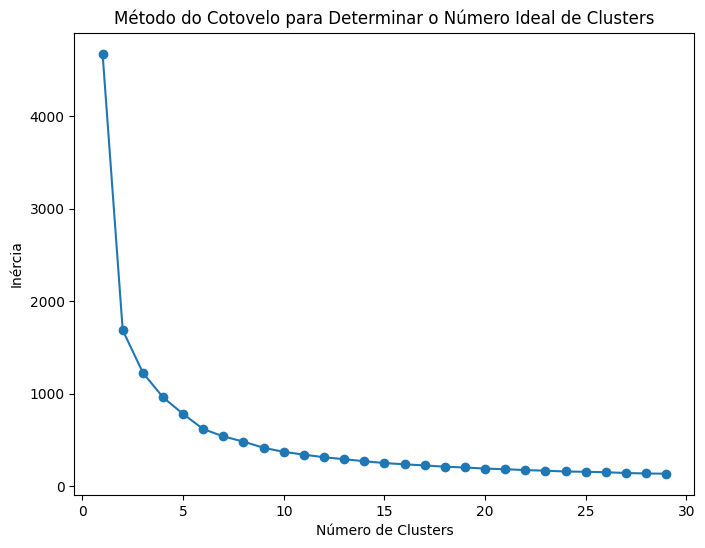

In [ ]:
# Redução de dimensionalidade usando PCA (opcional)
pca = PCA(n_components=2)  # Utiliza a técnica PCA para reduzir os vetores de compra para 2 dimensões
vetores_compra_reduzidos = pca.fit_transform(vetores_compra)  # Aplica a redução de dimensionalidade aos dados de compra

# Lista para armazenar os valores de inércia
inercia = []

# Testar diferentes números de clusters
valores_clusters = range(1, 30)
for numero_clusters in valores_clusters:
    kmeans = KMeans(n_clusters=numero_clusters, n_init=10)  # Cria o modelo KMeans com o número atual de clusters
    kmeans.fit(vetores_compra_reduzidos)  # Treina o modelo com os dados reduzidos
    inercia.append(kmeans.inertia_)  # Armazena a inércia (soma dos quadrados das distâncias aos centróides)

# Plotar o gráfico do cotovelo
plt.figure(figsize=(8, 6))
plt.plot(valores_clusters, inercia, marker='o')  # Cria um gráfico com número de clusters no eixo X e inércia no eixo Y
plt.xlabel('Número de Clusters')
plt.ylabel('Inércia')
plt.title('Método do Cotovelo para Determinar o Número Ideal de Clusters')  # Adiciona título ao gráfico
plt.show()  # Exibe o gráfico

##### Índice de Jaccard:


O Índice de Jaccard é uma métrica de similaridade que avalia a proximidade entre dois conjuntos de dados. Em nosso contexto, ele foi aplicado para calcular a semelhança entre os padrões de compra dos clientes.  
Quanto mais próximo o índice de Jaccard estiver de 1, maior é a semelhança entre os conjuntos de produtos comprados pelos clientes. Esta métrica foi crucial para agrupar clientes que compartilham padrões de compra similares,  
fornecendo uma base sólida para a formação de clusters distintos.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/pairwise.py:2025: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
<ipython-input-7-8f6cb650a580>:5: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  ligacao = linkage(distancias_jaccard, method='ward')


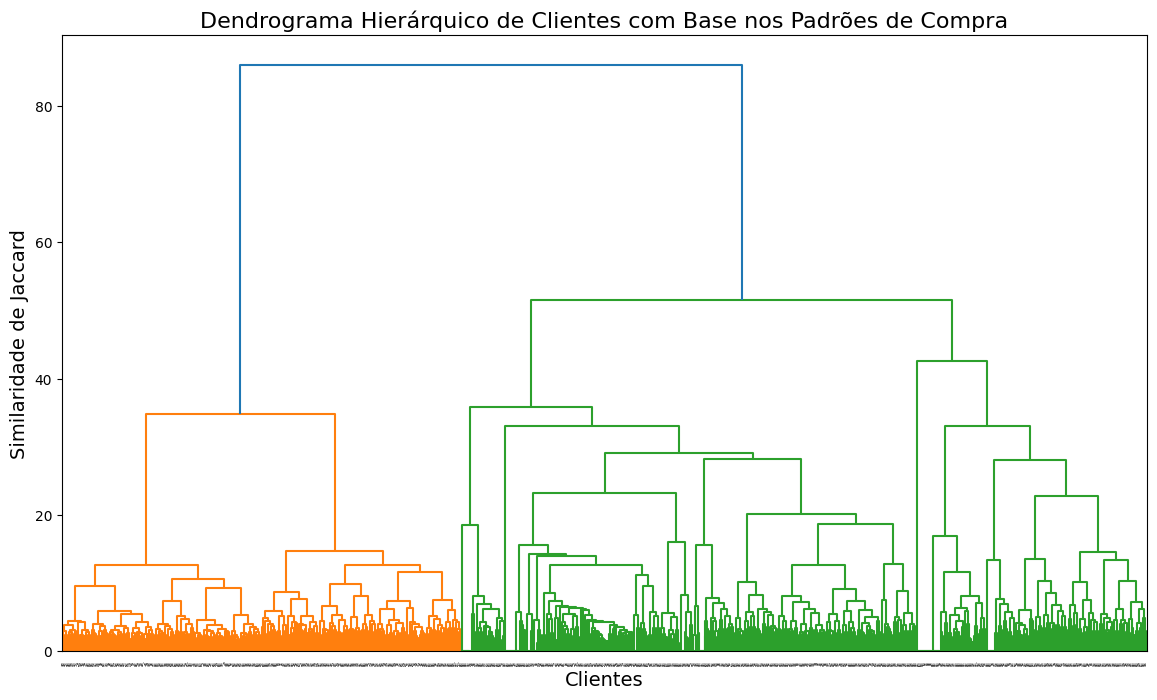

In [ ]:
# Calcular a matriz de distâncias usando o Índice de Jaccard como métrica
distancias_jaccard = pairwise_distances(vetores_compra, metric='jaccard')

# Calcular o linkage (ligação) usando o método de Ward
ligacao = linkage(distancias_jaccard, method='ward')

# Criar o dendrograma para visualizar a hierarquia dos clusters
plt.figure(figsize=(14, 8))
plt.title('Dendrograma Hierárquico de Clientes com Base nos Padrões de Compra', fontsize=16)
plt.xlabel('Clientes', fontsize=14)
plt.ylabel('Similaridade de Jaccard', fontsize=14)

# Plota o dendrograma com rotação dos rótulos e tamanho de fonte ajustados
dendrogram(ligacao, labels=compras_clientes['CODCLI'].values, leaf_rotation=90, leaf_font_size=1)

plt.show()  # Exibe o dendrograma


##### Conclusão:

Após uma análise detalhada dos gráficos, concluímos que o dendrograma gerado com a aplicação do índice de Jaccard é a escolha mais apropriada para o nosso conjunto de dados.  
Esta conclusão é fundamentada no fato de que o índice de Jaccard é especialmente adequado para dados binários, como os nossos, onde estamos interessados na presença ou ausência de produtos nos padrões de compra dos clientes.


Com base nessa observação, decidimos utilizar a técnica de segmentação de clientes, e optamos por dividir os clientes em 13 clusters distintos.  
Esse número de clusters foi escolhido após uma análise cuidadosa dos dendrogramas e do método do cotovelo, buscando um equilíbrio entre a precisão do modelo e sua capacidade de generalização para diferentes grupos de clientes.  
A segmentação em 13 clusters nos permitirá entender melhor os diferentes comportamentos de compra dos clientes, facilitando a personalização de estratégias de marketing e melhorando a experiência do cliente de forma mais eficaz e relevante.

# APLICANDO ALGORITIMO DE CLUSTERIZACAO KMEANS

### Definição do algoritimo

Nesta análise, aplicamos o algoritmo K-means para realizar a tarefa de clustering, um processo essencial para agrupar dados semelhantes em clusters distintos.   
O algoritmo K-means começa selecionando aleatoriamente K centróides iniciais, onde K é o número de clusters que você deseja criar.


O K-means trabalha agrupando os dados em grupos, fundamentado na similaridade entre os pontos de dados.  
Para facilitar a visualização desses clusters, utilizamos a técnica de Análise de Componentes Principais (PCA), que reduz a dimensionalidade dos dados para 2 dimensões.  
Essa redução torna possível a representação visual dos clusters em um gráfico bidimensional, fornecendo insights valiosos a partir de dados complexos.


Para atingir esse objetivo, aplicamos a PCA aos dados originais, especificamente aos vetores_compra, transformando-os em um conjunto bidimensional.  
Esse processo é crucial para compreender a distribuição dos clusters de forma intuitiva e, assim, orientar estratégias de negócios baseadas em padrões de compra similares dos clientes.  
A combinação de K-means com PCA não apenas simplifica a interpretação dos resultados, mas também abre portas para a personalização de abordagens de marketing e melhor compreensão dos comportamentos dos clientes.

In [ ]:
# Aplicar K-means para clustering
numero_clusters = 13
kmeans   = KMeans(n_clusters=numero_clusters, )

# Redução de dimensionalidade usando PCA (opcional)
pca = PCA(n_components=2)
vetores_compra_reduzidos = pca.fit_transform(vetores_compra)
clusters = kmeans.fit_predict(vetores_compra_reduzidos)

# Adicionar rótulos de cluster aos dados
compras_clientes['CLUSTER'] = clusters

# Criar base cluster
base_cluster = compras_clientes[["CODCLI","CLUSTER"]]

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [ ]:
# Adicione as coordenadas de PCA ao DataFrame
compras_clientes['PCA1'] = vetores_compra_reduzidos[:, 0]
compras_clientes['PCA2'] = vetores_compra_reduzidos[:, 1]
grafic_pca = compras_clientes[["CODCLI","PCA1","PCA2"]]
grafic_pca = pd.merge(grafic_pca, base_cluster, how="left", on="CODCLI")
grafic_pca = pd.merge(grafic_pca, base_clientes_produtos, how="left", on="CODCLI")
grafic_pca = grafic_pca[["CODCLI","CLUSTER","PCA1","PCA2","NAME_CAT"]].drop_duplicates()
grafic_pca = grafic_pca.groupby(["CODCLI", "CLUSTER", "PCA1", "PCA2"])['NAME_CAT'].apply(list).reset_index()

# Adicione quebra de linha à coluna NAME_CAT
grafic_pca['NAME_CAT'] = grafic_pca['NAME_CAT'].apply(lambda x: '<br>'.join(x))

# Crie a visualização interativa com Plotly Express usando o mapa de cores personalizado
fig = px.scatter(grafic_pca, x='PCA1', y='PCA2', color='CLUSTER', hover_data=['CODCLI', 'NAME_CAT'])
# Ajuste a altura do gráfico verticalmente
fig.update_layout(
    title='Visualização de Clusters com PCA',
    height=900  # Defina a altura desejada em pixels
)

fig.show()

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(vetores_compra_reduzidos, kmeans.labels_)
print("Coeficiente de silhueta:",silhouette_avg)

Coeficiente de silhueta: 0.3838974507492301


In [ ]:
tcluster_clientes = grafic_pca[["CLUSTER","CODCLI"]]
tcluster_clientes = tcluster_clientes.groupby(["CLUSTER"]).count().reset_index()
tcluster_sort = tcluster_clientes.sort_values(by='CODCLI', ascending=False)

#Coluna de porcentagem
tcluster_sort['%T'] = tcluster_sort['CODCLI'] / total_clientes

display(tcluster_sort)

,CLUSTER,CODCLI,%T
10,10,602,0.292375
1,1,344,0.167071
12,12,219,0.106362
7,7,189,0.091792
2,2,129,0.062652
9,9,94,0.045653
11,11,94,0.045653
4,4,87,0.042254
3,3,84,0.040797
0,0,71,0.034483


In [ ]:
cluster_cliente = grafic_pca[['CODCLI', 'CLUSTER']]
cluster_trans = pd.merge(cluster_cliente, base, how='right', on='CODCLI')
cluster_produt = cluster_trans[['CLUSTER', "CHAVE_SUB"]].drop_duplicates()

In [ ]:
tcluster_produt = cluster_produt.groupby(["CLUSTER"]).count().reset_index()
tprodut_sort = tcluster_produt.sort_values(by='CHAVE_SUB', ascending=False)

tprodut_sort["%T"] = tprodut_sort['CHAVE_SUB'] / total_produtos

display(tprodut_sort)
total_produtos

,CLUSTER,CHAVE_SUB,%T
3,3,355,0.690661
2,2,348,0.677043
0,0,341,0.663424
9,9,338,0.657588
8,8,336,0.653696
12,12,331,0.643969
7,7,327,0.636187
4,4,314,0.610895
10,10,312,0.607004
6,6,303,0.589494


514

In [ ]:
trans_cluster = cluster_trans[['CLUSTER', 'CODCLI', 'CHAVE_SUB', 'NOME_CONCAT']].drop_duplicates()

trans_cluster = trans_cluster.groupby(["CLUSTER", "CHAVE_SUB", 'NOME_CONCAT']).count().reset_index()

tcluster_sort = trans_cluster.sort_values(by='CODCLI', ascending=False)

tcluster_sort[tcluster_sort['CLUSTER']==2].head(10)

,CLUSTER,CHAVE_SUB,NOME_CONCAT,CODCLI
812,2,1002-1008-100801,GASTRONOMIA - CREME CULINARIO - LINHA FOOD 1KG,58
758,2,1002-100209-1016,GASTRONOMIA - OLEOS - SOJA,54
873,2,1002-1019-101901,GASTRONOMIA - GORDURAS - PALMA,54
962,2,1006-100601-100768,PANIFICACAO - MARGARINAS - LINHA FOOD 15KG,52
813,2,1002-100818-100819,GASTRONOMIA - ACUCAR - CRISTAL,50
665,2,1001-100101-100768,CONGELADOS - AVES - FILE DE PEITO,49
977,2,1006-90-901,PANIFICACAO - TRIGO - SEM FERMENTO,48
817,2,1002-100819-100820,GASTRONOMIA - SAL - REFINADO,47
855,2,1002-1011-100113,GASTRONOMIA - FARINHA - PANKO,42
772,2,1002-100210-1009,GASTRONOMIA - ATOMATADOS - KETCHUP SACHE,41


In [ ]:
trans_cluster = cluster_trans[['CLUSTER', 'CODCLI', 'CHAVE_SUB', 'NOME_CONCAT']].drop_duplicates()

trans_cluster = trans_cluster.groupby(["CLUSTER", "CHAVE_SUB", 'NOME_CONCAT']).count().reset_index()

tcluster_sort = trans_cluster.sort_values(by='CODCLI', ascending=False)

tcluster_sort[tcluster_sort['CLUSTER']==6].head(15)

,CLUSTER,CHAVE_SUB,NOME_CONCAT,CODCLI
2127,6,1002-11-118,GASTRONOMIA - MOLHOS - MOSTARDA,29
2058,6,1002-100819-100820,GASTRONOMIA - SAL - REFINADO,29
2054,6,1002-100818-100819,GASTRONOMIA - ACUCAR - CRISTAL,28
2093,6,1002-1011-100113,GASTRONOMIA - FARINHA - PANKO,27
2036,6,1002-1004-100402,GASTRONOMIA - ARROZ - BRANCO,27
2001,6,1002-100209-1016,GASTRONOMIA - OLEOS - SOJA,27
2025,6,1002-10022-100227,GASTRONOMIA - ORIENTAL - MOLHOS,26
2104,6,1002-1013-100134,GASTRONOMIA - FEIJÃO - PRETO,26
2102,6,1002-1013-100132,GASTRONOMIA - FEIJÃO - CARIOCA,26
2193,6,1006-100601-100768,PANIFICACAO - MARGARINAS - LINHA FOOD 15KG,25


In [ ]:
cluster_trans[cluster_trans['CODCLI'] == 597]

,CODCLI,CLUSTER,DTFAT,CHAVE_SUB,CODSEC,NOME_SECAO,CODCATEGORIA,NOME_CATEGORIA,CODSUBCATEGORIA,NOME_SUBCATEGORIA,PESOLIQ,NOME_CONCAT,NAME_CAT
8467,597,2,2022-10-11,1005-10058-100584,1005,CONFEITARIA,10058.0,LEITE CONDENSADO,100584.0,LINHA FOOD 5KG,7.142857,CONFEITARIA - LEITE CONDENSADO - LINHA FOOD 5KG,CON-LEITE CONDENSADO
10714,597,2,2022-10-13,1005-10058-100584,1005,CONFEITARIA,10058.0,LEITE CONDENSADO,100584.0,LINHA FOOD 5KG,14.285714,CONFEITARIA - LEITE CONDENSADO - LINHA FOOD 5KG,CON-LEITE CONDENSADO
14273,597,2,2022-10-15,1005-10058-100584,1005,CONFEITARIA,10058.0,LEITE CONDENSADO,100584.0,LINHA FOOD 5KG,14.285714,CONFEITARIA - LEITE CONDENSADO - LINHA FOOD 5KG,CON-LEITE CONDENSADO
15188,597,2,2022-10-18,1005-10058-100584,1005,CONFEITARIA,10058.0,LEITE CONDENSADO,100584.0,LINHA FOOD 5KG,14.285714,CONFEITARIA - LEITE CONDENSADO - LINHA FOOD 5KG,CON-LEITE CONDENSADO
33914,597,2,2022-11-04,0-2-21,0,REFRIGERADOS,2.0,MARGARINAS,21.0,FOLHADA,1.750286,REFRIGERADOS - MARGARINAS - FOLHADA,REF-MARGARINAS
33915,597,2,2022-11-04,1005-3-100532,1005,CONFEITARIA,3.0,ACUCAR,100532.0,CONFEITEIRO,1.428571,CONFEITARIA - ACUCAR - CONFEITEIRO,CON-ACUCAR
33916,597,2,2022-11-04,1005-5-50,1005,CONFEITARIA,5.0,DOCE DE LEITE,50.0,"9,8KG",2.800000,"CONFEITARIA - DOCE DE LEITE - 9,8KG",CON-DOCE DE LEITE
33917,597,2,2022-11-04,1006-100601-100772,1006,PANIFICACAO,100601.0,MARGARINAS,100772.0,LINHA FOOD 2KG,1.714286,PANIFICACAO - MARGARINAS - LINHA FOOD 2KG,PAN-MARGARINAS
41874,597,2,2022-11-11,1002-1019-101901,1002,GASTRONOMIA,1019.0,GORDURAS,101901.0,PALMA,4.142857,GASTRONOMIA - GORDURAS - PALMA,GAS-GORDURAS
41875,597,2,2022-11-11,1005-10060-100601,1005,CONFEITARIA,10060.0,CHANTILY,100601.0,TRADICIONAL,0.591429,CONFEITARIA - CHANTILY - TRADICIONAL,CON-CHANTILY


In [ ]:
tcluster_sort.to_excel('dados.xlsx', index=True)